<a href="https://colab.research.google.com/github/tamyriscabral/PFC2/blob/main/Gr%C3%A1ficos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# IMPORTS
# ============================================================
from pathlib import Path
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

In [2]:
# ============================================================
# CONFIGURAÇÃO DE CAMINHOS E DIRETÓRIOS
# ============================================================
ARQUIVO_DADOS = Path("data.xlsx")
ARQUIVO_LOCALIZACAO = Path("luminarias_com_localizacao_nova.csv")
PASTA_SAIDA = Path("/content/graficos")
PASTA_SAIDA.mkdir(exist_ok=True, parents=True)

# Configurações de visualização pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 120)

print("Bibliotecas carregadas.")
print(f"Gráficos serão salvos em: {PASTA_SAIDA}")

Bibliotecas carregadas.
Gráficos serão salvos em: /content/graficos


In [3]:
# ============================================================
# LEITURA DOS DADOS
# ============================================================
df = pd.read_excel(ARQUIVO_DADOS, sheet_name="Planilha1")

print("\nDimensões da base:")
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")


Dimensões da base:
Linhas: 11951
Colunas: 33


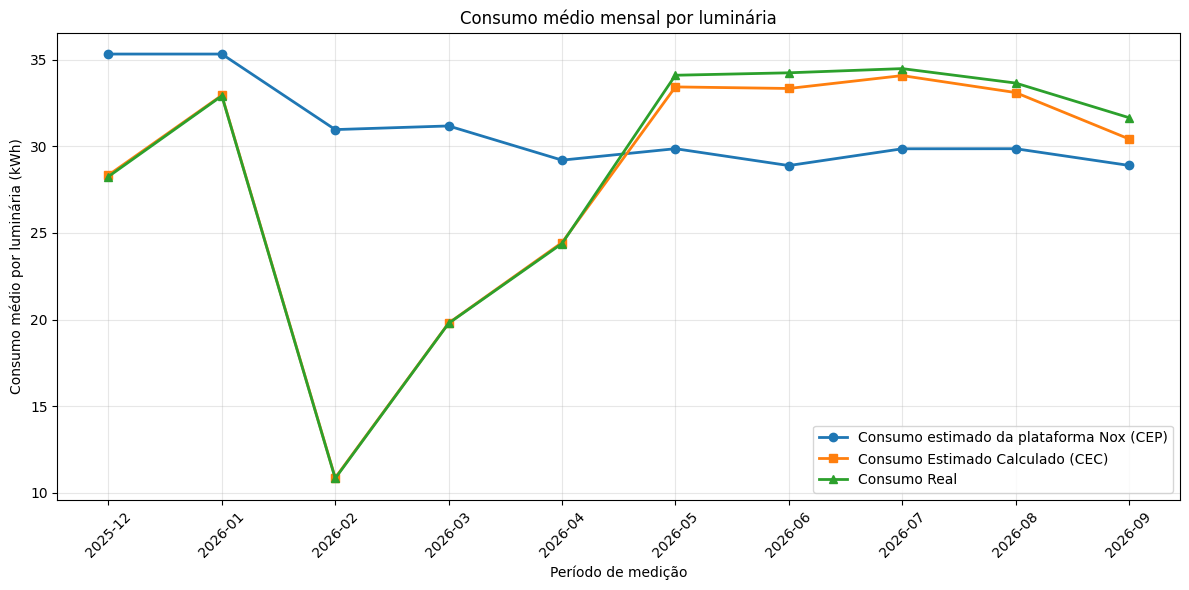

In [4]:
# ============================================================
# ANÁLISE E GERAÇÃO DE GRÁFICOS: CONSUMO MÉDIO MENSAL
# ============================================================
dados = df.copy()
colunas_consumo = [
    "Consumo Estimado (Wh) old",
    "Consumo Estimado Calculado (kWh)",
    "Consumo Real kWh"
]

for coluna in colunas_consumo:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")

dados["Data e hora final"] = pd.to_datetime(dados["Data e hora final"], errors="coerce")
dados = dados.dropna(subset=colunas_consumo + ["Data e hora final"]).copy()

dados["Estimado Original (kWh)"] = dados["Consumo Estimado (Wh) old"] / 1000
dados["Periodo"] = dados["Data e hora inicial"].dt.to_period("M")

mensal = (
    dados.groupby("Periodo")
    .agg(
        Estimado_Original=("Estimado Original (kWh)", "mean"),
        Estimado_Calculado=("Consumo Estimado Calculado (kWh)", "mean"),
        Consumo_Real=("Consumo Real kWh", "mean"),
        Quantidade_Registros=("ID Nox", "size"),
        Quantidade_Luminarias=("ID Nox", "nunique")
    )
    .reset_index()
)
mensal["Periodo"] = mensal["Periodo"].astype(str)

plt.figure(figsize=(12, 6))
plt.plot(mensal["Periodo"], mensal["Estimado_Original"], marker="o", linewidth=2, label="Consumo estimado da plataforma Nox (CEP)")
plt.plot(mensal["Periodo"], mensal["Estimado_Calculado"], marker="s", linewidth=2, label="Consumo Estimado Calculado (CEC)")
plt.plot(mensal["Periodo"], mensal["Consumo_Real"], marker="^", linewidth=2, label="Consumo Real")

plt.title("Consumo médio mensal por luminária")
plt.xlabel("Período de medição")
plt.ylabel("Consumo médio por luminária (kWh)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

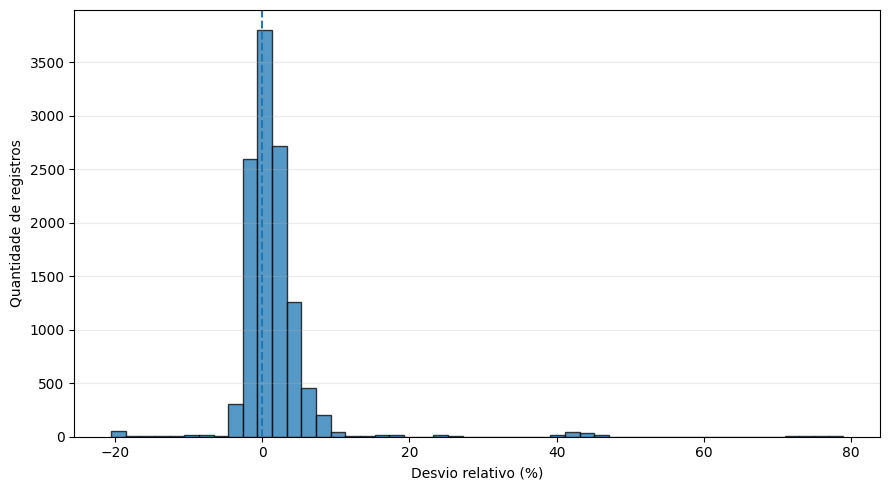

In [5]:
# ============================================================
# DISTRIBUIÇÃO DO DESVIO RELATIVO
# ============================================================
col_real = "Consumo Real kWh"
col_estimado = "Consumo Estimado Calculado (kWh)"

real = pd.to_numeric(df[col_real], errors="coerce")
estimado = pd.to_numeric(df[col_estimado], errors="coerce")

mascara_valida = estimado.notna() & (estimado > 0)
desvio_relativo = (real[mascara_valida] - estimado[mascara_valida]) / estimado[mascara_valida] * 100
desvio_relativo = desvio_relativo.replace([np.inf, -np.inf], np.nan).dropna()

limite_inferior = desvio_relativo.quantile(0.01)
limite_superior = desvio_relativo.quantile(0.99)
visivel = desvio_relativo[desvio_relativo.between(limite_inferior, limite_superior)]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(visivel, bins=50, edgecolor="black", alpha=0.75)
ax.axvline(0, linestyle="--", linewidth=1.5)
ax.set_xlabel("Desvio relativo (%)")
ax.set_ylabel("Quantidade de registros")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "distribuicao_desvio_relativo.png", dpi=300, bbox_inches="tight")
plt.show()

RESUMO POR POTÊNCIA CADASTRADA


,Registros,Mediana_calculada,Mediana_desvio_percentual,Minimo_calculado,Maximo_calculado
Potencia Cadastrada (W),,,,,
1,17,98.76,9776.25,77.84,108.96
30,120,70.25,134.17,49.84,79.58
70,4183,71.01,1.44,0.00,896.50
80,1950,78.08,-2.41,10.35,121.03
100,5604,98.92,-1.08,0.00,150.83


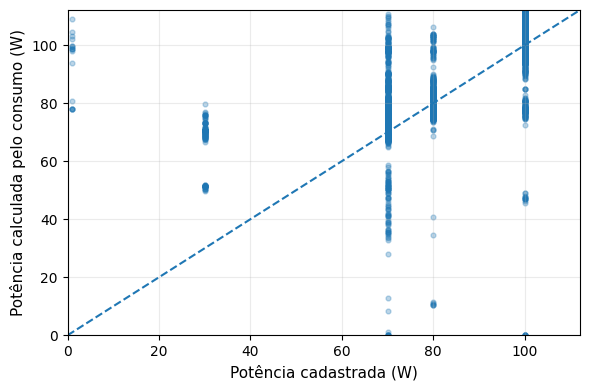

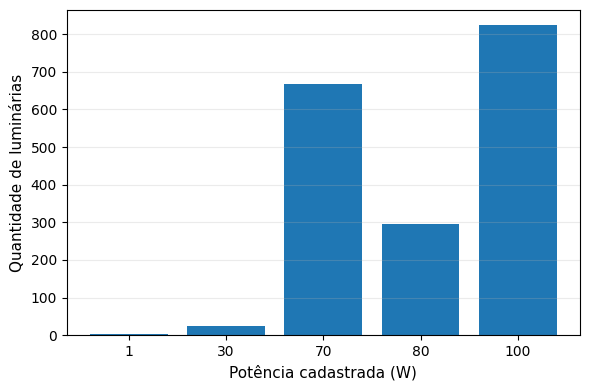

In [6]:

# ============================================
# ANÁLISE DA POTÊNCIA CADASTRADA
# ============================================

col_cadastrada = "Potencia Cadastrada (W)"
col_calculada = "Potência Calculada pelo Consumo (W)"

potencia = df[
    [
        "ID Nox",
        "Plaqueta",
        "Nome do Mês",
        col_cadastrada,
        col_calculada
    ]
].copy()

potencia[col_cadastrada] = pd.to_numeric(
    potencia[col_cadastrada], errors="coerce"
)
potencia[col_calculada] = pd.to_numeric(
    potencia[col_calculada], errors="coerce"
)

# Excluir infinitos apenas da comparação numérica
potencia[col_calculada] = potencia[col_calculada].replace(
    [np.inf, -np.inf], np.nan
)

potencia["Diferença de potência (W)"] = (
    potencia[col_calculada] - potencia[col_cadastrada]
)

potencia["Desvio de potência (%)"] = np.where(
    potencia[col_cadastrada] > 0,
    potencia["Diferença de potência (W)"]
    / potencia[col_cadastrada] * 100,
    np.nan
)

potencia_valida = potencia.dropna(
    subset=[col_cadastrada, col_calculada]
).copy()

# Resumo por potência cadastrada
resumo = potencia_valida.groupby(
    col_cadastrada
).agg(
    Registros=(col_calculada, "count"),
    Mediana_calculada=(col_calculada, "median"),
    Mediana_desvio_percentual=("Desvio de potência (%)", "median"),
    Minimo_calculado=(col_calculada, "min"),
    Maximo_calculado=(col_calculada, "max")
).sort_index()

print("RESUMO POR POTÊNCIA CADASTRADA")
display(resumo.round(2))

# Gráfico 1: potência cadastrada versus calculada
fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(
    potencia_valida[col_cadastrada],
    potencia_valida[col_calculada],
    alpha=0.3,
    s=12
)

maximo = max(
    potencia_valida[col_cadastrada].max(),
    potencia_valida[col_calculada].quantile(0.99)
)

ax.plot([0, maximo], [0, maximo], "--", linewidth=1.5)
ax.set_xlim(left=0, right=maximo)
ax.set_ylim(bottom=0, top=maximo)

# Identificação dos eixos
ax.set_xlabel("Potência cadastrada (W)", fontsize=11)
ax.set_ylabel("Potência calculada pelo consumo (W)", fontsize=11)

# Números dos eixos
ax.tick_params(axis="both", labelsize=10)

ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    PASTA_SAIDA / "potencia_cadastrada_vs_calculada.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Gráfico 2: distribuição das potências cadastradas
contagem = (
    df.groupby(col_cadastrada, dropna=False)["ID Nox"]
    .nunique()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    contagem.index.astype(str),
    contagem.values
)

ax.set_xlabel("Potência cadastrada (W)", fontsize=11)
ax.set_ylabel("Quantidade de luminárias", fontsize=11)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    PASTA_SAIDA / "distribuicao_potencia_cadastrada.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


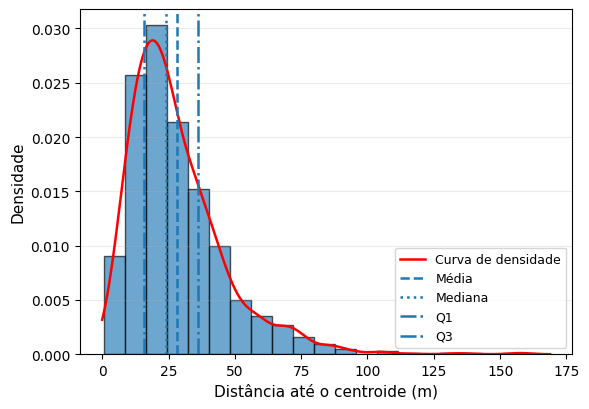

Geração de gráficos finalizada com sucesso.


In [7]:
# ============================================================
# ANÁLISE DE DISTÂNCIAS (LOCALIZAÇÃO)
# ============================================================
if ARQUIVO_LOCALIZACAO.exists():
    df_localizacao = pd.read_csv(ARQUIVO_LOCALIZACAO)
    distancias = pd.to_numeric(df_localizacao["Distância (m)"], errors="coerce").dropna().to_numpy()

    if len(distancias) > 0:
        minimo = np.min(distancias)
        q1 = np.percentile(distancias, 25)
        mediana = np.median(distancias)
        media = np.mean(distancias)
        q3 = np.percentile(distancias, 75)
        maximo = np.max(distancias)
        iiq = q3 - q1

        kde = gaussian_kde(distancias)
        x = np.linspace(0, maximo + 10, 500)
        densidade = kde(x)

        fig, ax = plt.subplots(figsize=(6, 4.2))
        ax.hist(distancias, bins=20, density=True, edgecolor="black", alpha=0.65)
        ax.plot(x, densidade, color="red", linewidth=1.8, label="Curva de densidade")

        for valor, nome, estilo in [(media, "Média", "--"), (mediana, "Mediana", ":"), (q1, "Q1", "-."), (q3, "Q3", "-.")]:
            ax.axvline(valor, linestyle=estilo, linewidth=1.8, label=nome)

        ax.set_xlabel("Distância até o centroide (m)", fontsize=11)
        ax.set_ylabel("Densidade", fontsize=11)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(loc="lower right", fontsize=9)
        plt.tight_layout()
        plt.savefig(PASTA_SAIDA / "06_distribuicao_distancias_com_densidade.png", dpi=300, bbox_inches="tight")
        plt.show()

print("Geração de gráficos finalizada com sucesso.")